In [58]:
import torch
from torch.distributions.multivariate_normal import MultivariateNormal
import math
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
import numpy as np

def lorenz96_rhs(x, F = 8.0):
    """
    Lorenz-96 vector field.

    x: Tensor of shape (..., N)
    F: scalar or tensor broadcastable to x[..., 0]

    Returns: dx/dt with same shape as x
    """
    # Periodic neighbors using roll
    x_ip1 = torch.roll(x, shifts=-1, dims=-1)  # x_{i+1}
    x_im1 = torch.roll(x, shifts=+1, dims=-1)  # x_{i-1}
    x_im2 = torch.roll(x, shifts=+2, dims=-1)  # x_{i-2}

    # dx_i/dt = (x_{i+1} - x_{i-2}) * x_{i-1} - x_i + F
    return (x_ip1 - x_im2) * x_im1 - x + torch.as_tensor(F, device=x.device, dtype=x.dtype)


def rk4_step(
    x,
    dt,
    rhs=lorenz96_rhs,
    rhs_args = (),
    rhs_kwargs = None,
):
    """
    One Runge-Kutta 4 step: x_{n+1} = x_n + dt/6*(k1 + 2k2 + 2k3 + k4).
    """
    if rhs_kwargs is None:
        rhs_kwargs = {}

    k1 = rhs(x, *rhs_args, **rhs_kwargs)
    k2 = rhs(x + 0.5 * dt * k1, *rhs_args, **rhs_kwargs)
    k3 = rhs(x + 0.5 * dt * k2, *rhs_args, **rhs_kwargs)
    k4 = rhs(x + dt * k3, *rhs_args, **rhs_kwargs)

    return x + (dt / 6.0) * (k1 + 2.0 * k2 + 2.0 * k3 + k4)


@torch.no_grad()
def integrate_lorenz96(
    x0,
    dt,
    steps,
    F = 8.0,
    save_every= 1,
):
    """
    Integrate Lorenz-96 forward with RK4.

    x0: (..., N) initial condition
    dt: timestep
    steps: number of RK4 steps
    F: forcing
    save_every: store every k-th step (including step 0)

    Returns:
      traj: (T, ..., N) where T = steps//save_every + 1
    """
    x = x0.clone()
    out = [x0.clone()]
    

    rhs_kwargs = {"F": F}
    for s in range(1, steps + 1):
        x = rk4_step(x, dt, rhs=lorenz96_rhs, rhs_kwargs=rhs_kwargs)
        if (s % save_every) == 0:
            out.append(x.clone())

    return torch.stack(out, dim=0)


# Example usage:
if __name__ == "__main__":
    device = "cuda" if torch.cuda.is_available() else "cpu"
    dtype = torch.float32

    B, N = 100, 40
    T_full = 550
    T_train = 500
    high = 10
    low = 6
    traj = torch.zeros(T_full+1,B,N)
    F_list = torch.zeros(B)
    
    for i in range(B):
        x0 = torch.randn(N, device=device, dtype=dtype)
        F_list[i] = (high-low)*torch.rand(1)+low
        traj[:,i,:] = integrate_lorenz96(x0, dt=0.01, steps=T_full, F=F_list[i], save_every=1)

In [ ]:
def pairwise_distances(X,Y):
    
    distance = torch.cdist(X,Y)
    
    return distance

def laplace_matrix(X,Y,sigma=1):
    
    D = pairwise_distances(X, Y)
    matrix = torch.exp(-D/sigma)
    
    return matrix

def gaussian_matrix(X,Y,sigma=1):
    
    D = pairwise_distances(X, Y)
    matrix = torch.exp(-D**2/(2*sigma**2))
    
    return matrix

def gaussian_prod_matrix(X,Y,sigma_u=1,sigma_F=1):
    
    D1 = pairwise_distances(X[:,:-1], Y[:,:-1])
    matrix1 = torch.exp(-D1**2/(2*sigma_u**2))

    D2 = pairwise_distances(X[:,-1][:,None], Y[:,-1][:,None])
    matrix2 = torch.exp(-D2**2/(2*sigma_F**2))
    
    matrix = matrix1*matrix2
    
    return matrix

def matern52_matrix(X,Y,sigma=1):
    
    D = pairwise_distances(X, Y)
    matrix = (1+math.sqrt(5)*D/sigma+5.0/3.0*D**2/sigma**2)*torch.exp(-math.sqrt(5)*D/sigma)
    
    return matrix

def poly_matrix(X,Y,c=0,d=1):
    
    inner = X @ Y.T
    
    matrix = (c+inner)**d
    
    return matrix

In [60]:
def kernel_regression(X_test,X_train,Y_train,lam=10**-5,kernel=gaussian_matrix, **kernel_params):
    
    K_test = kernel(X_test,X_train, **kernel_params)
    K_train = kernel(X_train,X_train, **kernel_params)
    I = torch.eye(K_train.shape[0], device=K_train.device, dtype=K_train.dtype)

    alpha = torch.linalg.solve(K_train + lam * I, Y_train)

    Y_test = K_test @ alpha

    return Y_test
    

In [167]:
L = 3

t0 = L - 1
t1 = T_train - 1
t_vals = list(range(t0, t1))
n_t = len(t_vals)

X = torch.zeros(B, n_t, N*L+1, device=traj.device, dtype=traj.dtype)
Y = torch.zeros(B, n_t, N)
for j in range(B):
    for i, t in enumerate(t_vals):
        window = traj[t-L+1:t+1, j, :]        # (L,p)
        window = torch.flip(window, dims=[0])    # newest->oldest
        X[j, i, :-1] = window.reshape(-1)
        Y[j, i, :] = traj[t+1, j, :]-traj[t, j, :]
    X[j,:,-1] = F_list[j]*torch.ones(n_t)  

In [ ]:
X_full = X.reshape(n_t*B,N*L+1)
Y_full = Y.reshape(n_t*B,N)

sample_size = 6000
idx = torch.randperm(X_full.shape[0], device=X_full.device)[:sample_size]

X_sample = X_full[idx]
Y_sample = Y_full[idx]

X_last = torch.zeros(B,N*L+1)
Y_last = torch.zeros(B,N)


for j in range(B):
    window = traj[T_train-L+1:T_train+1, j, :]        # (L,p)
    window = torch.flip(window, dims=[0])    # newest->oldest
    X_last[j, :-1] = window.reshape(-1)
    Y_last[j, :] = traj[T_train+1, j, :]-traj[T_train, j, :]
    X_last[j,-1] = F_list[j]

Xu = X_sample[:, :-1]
Du = torch.cdist(Xu, Xu)
sigma_u = torch.median(Du[Du > 0])

Xf = X_sample[:, -1]
Df = torch.cdist(Xf[:,None], Xf[:,None])
sigma_F = torch.median(Df[Df > 0])

Delta_t_next = kernel_regression(X_last,X_sample,Y_sample,lam=10**-5,kernel=gaussian_prod_matrix,sigma_u=sigma_u,sigma_F=sigma_F)

traj_next = traj[T_train,:,:] + Delta_t_next

In [169]:
# X_mean = X_sample.mean(dim=0, keepdim=True)
# X_std = X_sample.std(dim=0, keepdim=True).clamp_min(1e-6)
# Y_mean = Y_sample.mean(dim=0, keepdim=True)
# Y_std = Y_sample.std(dim=0, keepdim=True).clamp_min(1e-6)

# X_train_n = (X_sample - X_mean) / X_std
# Y_train_n = (Y_sample - Y_mean) / Y_std

# # for queries:
# x_query_n = (x_query - X_mean) / X_std

# delta_n = kernel_regression(
#     x_query_n, X_train_n, Y_train_n,
#     lam=1e-5,
#     kernel=gaussian_prod_matrix,
#     sigma_u=sigma_u,
#     sigma_F=sigma_F,
# )

# delta = delta_n * Y_std + Y_mean

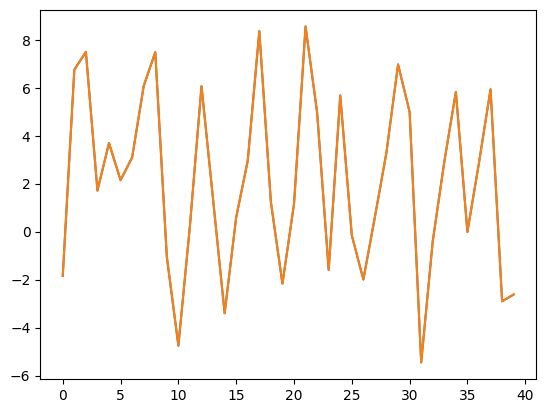

In [170]:
plt.plot(traj_next[5,:])
plt.plot(traj[T_train+1, 5, :])
#plt.plot(traj[T_train, 5, :])
#plt.plot(traj[540, 30, :])

In [171]:
traj_test_insample = torch.zeros(T_full+1,B,N)
F_test_insample = torch.zeros(B)

for i in range(B):
    x0 = torch.randn(N, device=device, dtype=dtype)
    F_test_insample[i] = (high-low)*torch.rand(1)+low
    traj_test_insample[:,i,:] = integrate_lorenz96(x0, dt=0.01, steps=T_full, F=F_test_insample[i], save_every=1)

In [172]:
X_test_insample = torch.zeros(B, n_t, N*L+1, device=traj.device, dtype=traj.dtype)

X_pred_insample = torch.zeros(B, n_t, N, device=traj.device, dtype=traj.dtype)
Y_test_insample = torch.zeros(B, n_t, N, device=traj.device, dtype=traj.dtype)
Delta_t_insample = torch.zeros(B,n_t, N, device=traj.device, dtype=traj.dtype)
for j in range(B):
    for i, t in enumerate(t_vals):
        window = traj_test_insample[t-L+1:t+1, j, :]        # (L,p)
        window = torch.flip(window, dims=[0])    # newest->oldest
        X_test_insample[j, i, :-1] = window.reshape(-1)
        Y_test_insample[j, i, :] = traj_test_insample[t+1, j, :]-traj_test_insample[t, j, :]
        X_test_insample[j,i,-1] = F_test_insample[j]
    Delta_t_insample[j,:,:] = kernel_regression(X_test_insample[j,:,:],X_sample,Y_sample,lam=10**-5,kernel=gaussian_prod_matrix,sigma_u=sigma_u,sigma_F=sigma_F)
    X_pred_insample[j,:,:] = traj_test_insample[t_vals,j,:]+Delta_t_insample[j,:,:]


In [173]:

horizon = 20

# traj_test_insample: [T, B, N]
# Assume T_train is the last in-sample index used as current time
# Need L past states ending at T_train
window = traj_test_insample[T_train - L + 1 : T_train + 1].flip(0).clone()   # [L, B, N], newest -> oldest

# Outputs
X_forecast_insample = torch.zeros(B, horizon, N, device=traj_test_insample.device, dtype=traj_test_insample.dtype)
X_test_insample     = torch.zeros(B, horizon, L * N + 1, device=traj_test_insample.device, dtype=traj_test_insample.dtype)
Y_test_insample     = torch.zeros(B, horizon, N, device=traj_test_insample.device, dtype=traj_test_insample.dtype)
Delta_t_insample    = torch.zeros(B, horizon, N, device=traj_test_insample.device, dtype=traj_test_insample.dtype)

for i in range(horizon):
    # window: [L, B, N] -> [B, L, N] -> [B, L*N]
    x_hist = window.permute(1, 0, 2).reshape(B, L * N)

    # append parameter/forcing feature
    # F_test_insample assumed shape [B]
    x_query = torch.cat([x_hist, F_test_insample[:, None]], dim=1)   # [B, L*N+1]
    X_test_insample[:, i, :] = x_query

    # true target increment, only for evaluation
    Y_test_insample[:, i, :] = (
        traj_test_insample[T_train + i + 1] - traj_test_insample[T_train + i]
    )

    # batched regression: should return [B, N]
    delta = kernel_regression(
        x_query,
        X_sample,
        Y_sample,
        lam=1e-5,
        kernel=gaussian_prod_matrix,
        sigma_u=sigma_u,
        sigma_F=sigma_F,
    )

    Delta_t_insample[:, i, :] = delta

    # current state is the newest one in the window
    current_state = window[0]                       # [B, N]
    next_state = current_state + delta             # [B, N]
    X_forecast_insample[:, i, :] = next_state

    # shift window down: newest stays at index 0
    window[1:] = window[:-1].clone()
    window[0] = next_state


In [174]:
X_forecast_insample.shape

torch.Size([100, 20, 40])

In [175]:
traj_test_insample[t0+1:t1+1,:,:].shape

torch.Size([497, 100, 40])

In [176]:
y_true = traj_test_insample[T_train+1:T_train+horizon+1].permute(1, 0, 2)

rel_err = torch.linalg.norm(X_forecast_insample - y_true) / torch.linalg.norm(y_true)
print("Relative error:", rel_err.item())

Relative error: 0.10160098969936371


In [177]:
y_true = traj_test_insample[T_train+1:T_train+horizon+1].permute(1, 0, 2)  # [B,h,N]

num = torch.linalg.norm(X_forecast_insample - y_true, dim=(0, 2))   # [h]
den = torch.linalg.norm(y_true, dim=(0, 2))                         # [h]
rel_err_model_per_step = num / den

print(rel_err_model_per_step)   # shape [h]

tensor([0.0083, 0.0169, 0.0258, 0.0347, 0.0436, 0.0524, 0.0611, 0.0698, 0.0784,
        0.0868, 0.0952, 0.1034, 0.1116, 0.1196, 0.1275, 0.1353, 0.1431, 0.1507,
        0.1583, 0.1658])


Text(0, 0.5, 'x(t)')

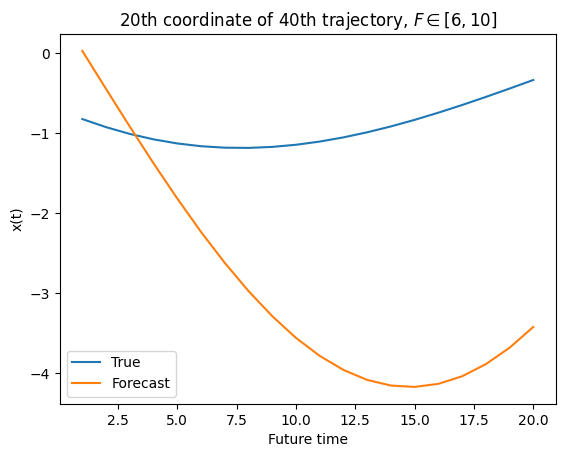

In [178]:
steps = torch.arange(1, horizon + 1).cpu()

plt.plot(steps,y_true[40,:,20])
plt.plot(steps,X_forecast_insample[39,:,19])
plt.legend(['True','Forecast'])
plt.title('20th coordinate of 40th trajectory, $F \in [6,10]$')
plt.xlabel('Future time')
plt.ylabel('x(t)')

In [179]:
x0 = traj_test_insample[T_train]                                             # [B,N]
X_persist = x0[:, None, :].repeat(1, horizon, 1)                             # [B,h,N]

rel_err_persist = torch.linalg.norm(X_persist - y_true) / torch.linalg.norm(y_true)
print("Persistence relative error:", rel_err_persist.item())

Persistence relative error: 0.4908006191253662


In [180]:
rel_err_persist_per_step = (
    torch.linalg.norm(X_persist - y_true, dim=(0, 2)) /
    torch.linalg.norm(y_true, dim=(0, 2))
)

print(rel_err_persist_per_step.shape)   # [horizon]
print(rel_err_persist_per_step)

torch.Size([20])
tensor([0.0447, 0.0893, 0.1338, 0.1781, 0.2219, 0.2653, 0.3081, 0.3502, 0.3915,
        0.4319, 0.4714, 0.5098, 0.5472, 0.5834, 0.6184, 0.6522, 0.6849, 0.7162,
        0.7464, 0.7753])


In [181]:

rel_err_traj_step = (
    torch.linalg.norm(X_forecast_insample - y_true, dim=2) /
    torch.linalg.norm(y_true, dim=2)
)  # [B,h]
mean_err_per_traj = rel_err_traj_step.mean(dim=1)   # [B]
worst_traj = torch.argmax(mean_err_per_traj)
print("Worst trajectory index:", worst_traj.item())
print("Worst trajectory mean rel err:", mean_err_per_traj[worst_traj].item())

Worst trajectory index: 70
Worst trajectory mean rel err: 0.15869829058647156


In [182]:
abs_err = torch.abs(X_forecast_insample - y_true)   # [B,h,N]

print("Mean absolute error:", abs_err.mean().item())
print("Median absolute error:", abs_err.median().item())
print("95th percentile abs error:", torch.quantile(abs_err.reshape(-1), 0.95).item())
print("99th percentile abs error:", torch.quantile(abs_err.reshape(-1), 0.99).item())

Mean absolute error: 0.2705793082714081
Median absolute error: 0.15549206733703613
95th percentile abs error: 0.9143496751785278
99th percentile abs error: 1.6936023235321045


In [183]:
sq_err = (X_forecast_insample - y_true)**2              # [B,h,N]
mean_sq_err_bn = sq_err.mean(dim=1)                     # [B,N]
flat_idx = torch.argmax(mean_sq_err_bn)
b_worst = flat_idx // N
n_worst = flat_idx % N

print("Worst trajectory:", b_worst.item())
print("Worst coordinate:", n_worst.item())

Worst trajectory: 70
Worst coordinate: 14


In [184]:
print("Mean |truth|:", y_true.abs().mean().item())
print("Median |truth|:", y_true.abs().median().item())
print("95th percentile |truth|:", torch.quantile(y_true.abs().reshape(-1), 0.95).item())

Mean |truth|: 3.498297691345215
Median |truth|: 2.9638872146606445
95th percentile |truth|: 8.471461296081543


In [185]:
pair_rel = (
    torch.linalg.norm(X_forecast_insample - y_true, dim=1) /
    torch.linalg.norm(y_true, dim=1)
)  # [B,N]

print("Median pair rel err:", pair_rel.median().item())
print("95th percentile pair rel err:", torch.quantile(pair_rel.reshape(-1), 0.95).item())
print("Fraction > 0.5:", (pair_rel > 0.5).float().mean().item())
print("Fraction > 1.0:", (pair_rel > 1.0).float().mean().item())

Median pair rel err: 0.08035667985677719
95th percentile pair rel err: 0.4778311550617218
Fraction > 0.5: 0.04475000128149986
Fraction > 1.0: 0.010499999858438969


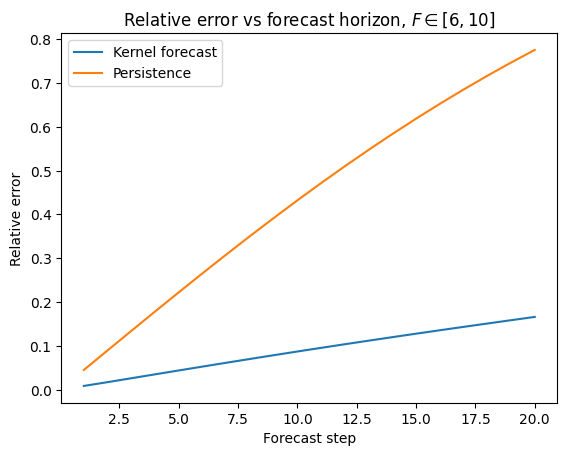

In [186]:


plt.plot(steps, rel_err_model_per_step.cpu(), label="Kernel forecast")
plt.plot(steps, rel_err_persist_per_step.cpu(), label="Persistence")
plt.xlabel("Forecast step")
plt.ylabel("Relative error")
plt.title(r"Relative error vs forecast horizon, $F \in [6,10]$")
plt.legend()
plt.show()

In [187]:
high_test = 12
low_test = 16

traj_test_outsample = torch.zeros(T_full+1,B,N)
F_test_outsample = torch.zeros(B)

for i in range(B):
    x0 = torch.randn(N, device=device, dtype=dtype)
    F_test_outsample[i] = (high_test-low_test)*torch.rand(1)+low_test
    traj_test_outsample[:,i,:] = integrate_lorenz96(x0, dt=0.01, steps=T_full, F=F_test_outsample[i], save_every=1)

In [188]:
X_test_outsample = torch.zeros(B, n_t, N*L+1, device=traj.device, dtype=traj.dtype)

X_pred_outsample = torch.zeros(B, n_t, N, device=traj.device, dtype=traj.dtype)
Y_test_outsample = torch.zeros(B, n_t, N, device=traj.device, dtype=traj.dtype)
Delta_t_outsample = torch.zeros(B,n_t, N, device=traj.device, dtype=traj.dtype)
for j in range(B):
    for i, t in enumerate(t_vals):
        window = traj_test_outsample[t-L+1:t+1, j, :]        # (L,p)
        window = torch.flip(window, dims=[0])    # newest->oldest
        X_test_outsample[j, i, :-1] = window.reshape(-1)
        Y_test_outsample[j, i, :] = traj_test_outsample[t+1, j, :]-traj_test_outsample[t, j, :]
        X_test_outsample[j,i,-1] = F_test_outsample[j]
    Delta_t_outsample[j,:,:] = kernel_regression(X_test_outsample[j,:,:],X_sample,Y_sample,lam=10**-5,kernel=gaussian_prod_matrix,sigma_u=sigma_u,sigma_F=sigma_F)
    X_pred_outsample[j,:,:] = traj_test_outsample[t_vals,j,:]+Delta_t_outsample[j,:,:]

In [189]:
# step_error_outsample = torch.linalg.norm(Delta_t_outsample-Y_test_outsample)/torch.linalg.norm(Y_test_outsample)
# print(step_error_outsample)

In [190]:
# model_error_outsample = torch.linalg.norm(torch.permute(X_pred_outsample,(1,0,2))-traj_test_outsample[t0+1:t1+1,:,:])/torch.linalg.norm(traj_test_outsample[t_vals,:,:])
# print(model_error_outsample)

In [191]:
# pers_error_outsample = torch.linalg.norm(traj_test_outsample[t_vals,:,:]-traj_test_outsample[t0+1:t1+1,:,:])/torch.linalg.norm(traj_test_outsample[t_vals,:,:])
# print(pers_error_outsample)

In [192]:

horizon = 20

# traj_test_insample: [T, B, N]
# Assume T_train is the last in-sample index used as current time
# Need L past states ending at T_train
window = traj_test_outsample[T_train - L + 1 : T_train + 1].flip(0).clone()   # [L, B, N], newest -> oldest

# Outputs
X_forecast_outsample = torch.zeros(B, horizon, N, device=traj_test_outsample.device, dtype=traj_test_outsample.dtype)
X_test_outsample     = torch.zeros(B, horizon, L * N + 1, device=traj_test_outsample.device, dtype=traj_test_outsample.dtype)
Y_test_outsample     = torch.zeros(B, horizon, N, device=traj_test_outsample.device, dtype=traj_test_outsample.dtype)
Delta_t_outsample    = torch.zeros(B, horizon, N, device=traj_test_outsample.device, dtype=traj_test_outsample.dtype)

for i in range(horizon):
    # window: [L, B, N] -> [B, L, N] -> [B, L*N]
    x_hist = window.permute(1, 0, 2).reshape(B, L * N)

    # append parameter/forcing feature
    # F_test_insample assumed shape [B]
    x_query = torch.cat([x_hist, F_test_outsample[:, None]], dim=1)   # [B, L*N+1]
    X_test_outsample[:, i, :] = x_query

    # true target increment, only for evaluation
    Y_test_outsample[:, i, :] = (
        traj_test_outsample[T_train + i + 1] - traj_test_outsample[T_train + i]
    )

    # batched regression: should return [B, N]
    delta = kernel_regression(
        x_query,
        X_sample,
        Y_sample,
        lam=1e-5,
        kernel=gaussian_prod_matrix,
        sigma_u=sigma_u,
        sigma_F=sigma_F,
    )

    Delta_t_outsample[:, i, :] = delta

    # current state is the newest one in the window
    current_state = window[0]                       # [B, N]
    next_state = current_state + delta             # [B, N]
    X_forecast_outsample[:, i, :] = next_state

    # shift window down: newest stays at index 0
    window[1:] = window[:-1].clone()
    window[0] = next_state

In [193]:
y_true = traj_test_outsample[T_train+1:T_train+horizon+1].permute(1, 0, 2)

rel_err = torch.linalg.norm(X_forecast_outsample - y_true) / torch.linalg.norm(y_true)
print("Relative error:", rel_err.item())

Relative error: 0.3583671748638153


In [194]:
y_true = traj_test_outsample[T_train+1:T_train+horizon+1].permute(1, 0, 2)  # [B,h,N]

num = torch.linalg.norm(X_forecast_outsample - y_true, dim=(0, 2))   # [h]
den = torch.linalg.norm(y_true, dim=(0, 2))                         # [h]
rel_err_model_per_step = num / den

print(rel_err_model_per_step)   # shape [h]

tensor([0.0309, 0.0624, 0.0943, 0.1259, 0.1572, 0.1881, 0.2187, 0.2489, 0.2788,
        0.3082, 0.3372, 0.3657, 0.3939, 0.4216, 0.4490, 0.4761, 0.5028, 0.5292,
        0.5554, 0.5812])


In [195]:
x0 = traj_test_outsample[T_train]                                             # [B,N]
X_persist = x0[:, None, :].repeat(1, horizon, 1)                             # [B,h,N]

rel_err_persist = torch.linalg.norm(X_persist - y_true) / torch.linalg.norm(y_true)
print("Persistence relative error:", rel_err_persist.item())

Persistence relative error: 0.6730393171310425


In [196]:
rel_err_persist_per_step = (
    torch.linalg.norm(X_persist - y_true, dim=(0, 2)) /
    torch.linalg.norm(y_true, dim=(0, 2))
)

print(rel_err_persist_per_step.shape)   # [horizon]
print(rel_err_persist_per_step)

torch.Size([20])
tensor([0.0682, 0.1359, 0.2026, 0.2681, 0.3321, 0.3943, 0.4545, 0.5126, 0.5683,
        0.6215, 0.6721, 0.7201, 0.7654, 0.8080, 0.8480, 0.8853, 0.9201, 0.9525,
        0.9826, 1.0105])


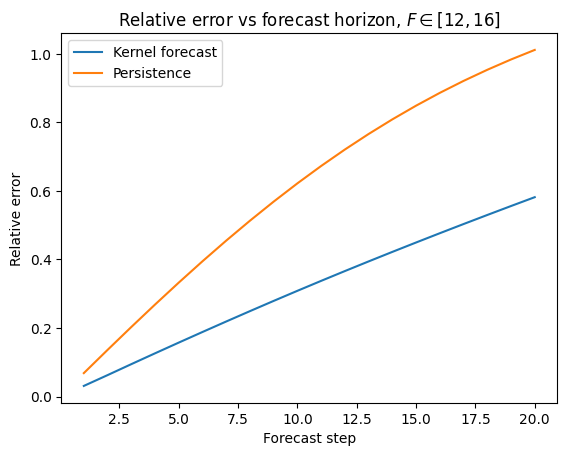

In [197]:
steps = torch.arange(1, horizon + 1).cpu()


plt.plot(steps, rel_err_model_per_step.cpu(), label="Kernel forecast")
plt.plot(steps, rel_err_persist_per_step.cpu(), label="Persistence")
plt.xlabel("Forecast step")
plt.ylabel("Relative error")
plt.title(r"Relative error vs forecast horizon, $F \in [12,16]$")
plt.legend()
plt.show()

Text(0, 0.5, 'x(t)')

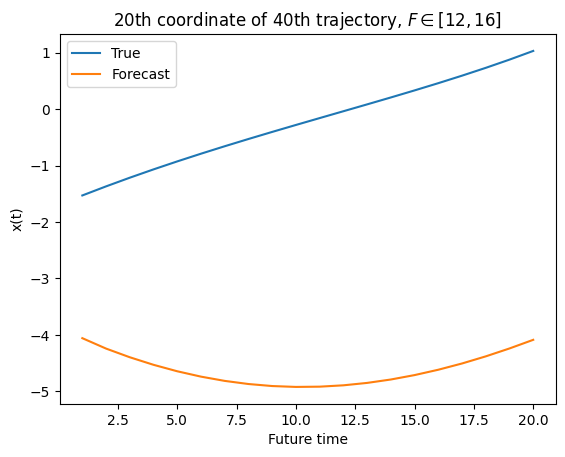

In [198]:
steps = torch.arange(1, horizon + 1).cpu()

plt.plot(steps,y_true[40,:,20])
plt.plot(steps,X_forecast_outsample[39,:,19])
plt.legend(['True','Forecast'])
plt.title('20th coordinate of 40th trajectory, $F \in [12,16]$')
plt.xlabel('Future time')
plt.ylabel('x(t)')

In [199]:

rel_err_traj_step = (
    torch.linalg.norm(X_forecast_insample - y_true, dim=2) /
    torch.linalg.norm(y_true, dim=2)
)  # [B,h]
mean_err_per_traj = rel_err_traj_step.mean(dim=1)   # [B]
worst_traj = torch.argmax(mean_err_per_traj)
print("Worst trajectory index:", worst_traj.item())
print("Worst trajectory mean rel err:", mean_err_per_traj[worst_traj].item())

Worst trajectory index: 19
Worst trajectory mean rel err: 1.2406010627746582


In [200]:
num = torch.linalg.norm(X_forecast_outsample - y_true, dim=0)   # [h,N]
den = torch.linalg.norm(y_true, dim=0)                         # [h,N]
rel_err_coord_step = num / den  
mean_err_per_coord = rel_err_coord_step.mean(dim=0)  # [N]
worst_coord = torch.argmax(mean_err_per_coord)
print("Worst coordinate:", worst_coord.item())
print("Worst coordinate mean rel err:", mean_err_per_coord[worst_coord].item())

Worst coordinate: 14
Worst coordinate mean rel err: 0.41250601410865784


In [201]:
abs_err = torch.abs(X_forecast_outsample - y_true)   # [B,h,N]

print("Mean absolute error:", abs_err.mean().item())
print("Median absolute error:", abs_err.median().item())
print("95th percentile abs error:", torch.quantile(abs_err.reshape(-1), 0.95).item())
print("99th percentile abs error:", torch.quantile(abs_err.reshape(-1), 0.99).item())

Mean absolute error: 1.4007658958435059
Median absolute error: 0.7687520980834961
95th percentile abs error: 4.951529502868652
99th percentile abs error: 8.873483657836914


In [202]:
sq_err = (X_forecast_outsample - y_true)**2              # [B,h,N]
mean_sq_err_bn = sq_err.mean(dim=1)                     # [B,N]
flat_idx = torch.argmax(mean_sq_err_bn)
b_worst = flat_idx // N
n_worst = flat_idx % N

print("Worst trajectory:", b_worst.item())
print("Worst coordinate:", n_worst.item())

Worst trajectory: 69
Worst coordinate: 6


In [203]:
print("Mean |truth|:", y_true.abs().mean().item())
print("Median |truth|:", y_true.abs().median().item())
print("95th percentile |truth|:", torch.quantile(y_true.abs().reshape(-1), 0.95).item())

Mean |truth|: 5.1606221199035645
Median |truth|: 4.419704437255859
95th percentile |truth|: 12.57408332824707


In [204]:
pair_rel = (
    torch.linalg.norm(X_forecast_outsample - y_true, dim=1) /
    torch.linalg.norm(y_true, dim=1)
)  # [B,N]

print("Median pair rel err:", pair_rel.median().item())
print("95th percentile pair rel err:", torch.quantile(pair_rel.reshape(-1), 0.95).item())
print("Fraction > 0.5:", (pair_rel > 0.5).float().mean().item())
print("Fraction > 1.0:", (pair_rel > 1.0).float().mean().item())

Median pair rel err: 0.2880299687385559
95th percentile pair rel err: 1.2218745946884155
Fraction > 0.5: 0.30524998903274536
Fraction > 1.0: 0.08874999731779099
